In [2]:
import pandas as pd

file_path = "../data/Netflix_Content_Analysis_1500_Records.xlsx"
df = pd.read_excel(file_path)
df.head()

,Show ID,Title,Type,Genre,Country,Rating,Date Added,Year Added,Release Year,Duration,Director,Description
0,NX0001,Shadow Memories 0001,TV Show,Action,South Korea,TV-MA,2021-09-10,2021,2008,1 Season,L. Wilson,Fictional record for portfolio analysis
1,NX0002,Last Journey 0002,Movie,Other,South Korea,TV-MA,2022-05-08,2022,2015,166 min,L. Wilson,Fictional record for portfolio analysis
2,NX0003,Summer Promise 0003,TV Show,Action,South Korea,TV-PG,2016-03-28,2016,2010,1 Season,J. Carter,Fictional record for portfolio analysis
3,NX0004,Blue Journey 0004,Movie,Romance,United States,PG-13,2023-02-10,2023,1999,75 min,L. Wilson,Fictional record for portfolio analysis
4,NX0005,Echoes of Road 0005,TV Show,Drama,India,TV-14,2017-01-28,2017,2002,8 Seasons,J. Carter,Fictional record for portfolio analysis


In [4]:
print(df.columns.tolist())#This shows every column available for our analysis.

['Show ID', 'Title', 'Type', 'Genre', 'Country', 'Rating', 'Date Added', 'Year Added', 'Release Year', 'Duration', 'Director', 'Description']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Show ID       1500 non-null   str           
 1   Title         1500 non-null   str           
 2   Type          1500 non-null   str           
 3   Genre         1500 non-null   str           
 4   Country       1500 non-null   str           
 5   Rating        1500 non-null   str           
 6   Date Added    1500 non-null   datetime64[us]
 7   Year Added    1500 non-null   int64         
 8   Release Year  1500 non-null   int64         
 9   Duration      1500 non-null   str           
 10  Director      1500 non-null   str           
 11  Description   1500 non-null   str           
dtypes: datetime64[us](1), int64(2), str(9)
memory usage: 295.4 KB


In [6]:
# checking missing values
df.isnull().sum()

Show ID         0
Title           0
Type            0
Genre           0
Country         0
Rating          0
Date Added      0
Year Added      0
Release Year    0
Duration        0
Director        0
Description     0
dtype: int64

In [7]:
# This counts rows that are exact duplicates of earlier rows.
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df.shape

(1500, 12)

In [9]:
df.columns.tolist()

['Show ID',
 'Title',
 'Type',
 'Genre',
 'Country',
 'Rating',
 'Date Added',
 'Year Added',
 'Release Year',
 'Duration',
 'Director',
 'Description']

In [11]:
# checking missing values 
print("Missing values in each column: ")
print(df.isnull().sum())

# checking complete duplicate rows
print("\n Duplicate rows: ",df.duplicated().sum())

# checking duplicate Show IDs
print("Duplicate Show IDs: ",df["Show ID"].duplicated().sum())

Missing values in each column: 
Show ID         0
Title           0
Type            0
Genre           0
Country         0
Rating          0
Date Added      0
Year Added      0
Release Year    0
Duration        0
Director        0
Description     0
dtype: int64

 Duplicate rows:  0
Duplicate Show IDs:  0


In [12]:
df['Type'].value_counts()

Type
Movie      1026
TV Show     474
Name: count, dtype: int64

In [14]:
df['Rating'].value_counts()

Rating
TV-MA    507
TV-14    437
TV-PG    216
R        157
PG-13    122
PG        35
G         16
TV-Y7     10
Name: count, dtype: int64

In [15]:
# What years are covered?
print("Earliest release year:", df["Release Year"].min())
print("Latest release year:", df["Release Year"].max())

print("Earliest year added:", df["Year Added"].min())
print("Latest year added:", df["Year Added"].max())

Earliest release year: 1992
Latest release year: 2025
Earliest year added: 2016
Latest year added: 2025


In [16]:
# Show five random records
df.sample(5, random_state=42)

,Show ID,Title,Type,Genre,Country,Rating,Date Added,Year Added,Release Year,Duration,Director,Description
1116,NX1117,Wild Journey 1117,TV Show,Drama,United States,TV-MA,2020-08-25,2020,2012,8 Seasons,A. Sharma,Fictional record for portfolio analysis
1368,NX1369,Silent Road 1369,Movie,Drama,India,TV-14,2018-02-25,2018,2000,119 min,N. Brown,Fictional record for portfolio analysis
422,NX0423,Summer Worlds 0423,Movie,Drama,Germany,TV-14,2021-05-20,2021,2003,160 min,J. Carter,Fictional record for portfolio analysis
413,NX0414,Fading Memories 0414,Movie,Romance,United States,PG,2022-10-16,2022,2013,150 min,S. Kim,Fictional record for portfolio analysis
451,NX0452,Midnight Legacy 0452,Movie,Action,India,TV-MA,2020-09-14,2020,2008,89 min,N. Brown,Fictional record for portfolio analysis


In [17]:
# Total titles
total_titles = len(df)

# Number of movies
total_movies = (df["Type"] == "Movie").sum()

# Number of TV shows
total_tv_shows = (df["Type"] == "TV Show").sum()

# Number of unique genres
total_genres = df["Genre"].nunique()

# Number of unique countries
total_countries = df["Country"].nunique()

# Print the KPIs
print("Total Titles:", total_titles)
print("Total Movies:", total_movies)
print("Total TV Shows:", total_tv_shows)
print("Unique Genres:", total_genres)
print("Unique Countries:", total_countries)

Total Titles: 1500
Total Movies: 1026
Total TV Shows: 474
Unique Genres: 7
Unique Countries: 10


In [18]:
yearly_content = df["Year Added"].value_counts().sort_index()

print(yearly_content)

Year Added
2016    125
2017    138
2018    160
2019    152
2020    158
2021    162
2022    159
2023    165
2024    148
2025    133
Name: count, dtype: int64


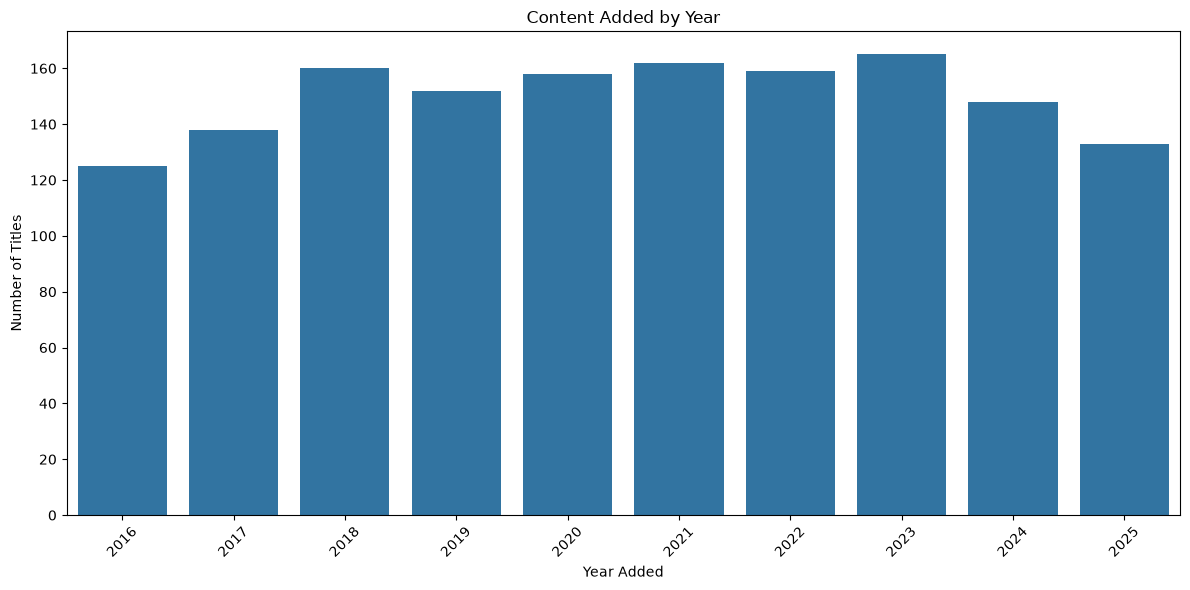

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Year Added"
)

plt.title("Content Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Analyze Movies vs. TV Shows

In [20]:
# Calculate percentages
type_counts = df["Type"].value_counts()

type_percentages = (
    df['Type'].value_counts(normalize=True)*100
).round(2)

print("Content counts: ")
print(type_counts)

print("\nContent percentages: ")
print(type_percentages)
# This calculates the percentage of records belonging to each content type


Content counts: 
Type
Movie      1026
TV Show     474
Name: count, dtype: int64

Content percentages: 
Type
Movie      68.4
TV Show    31.6
Name: proportion, dtype: float64


## Create Bar Charts 

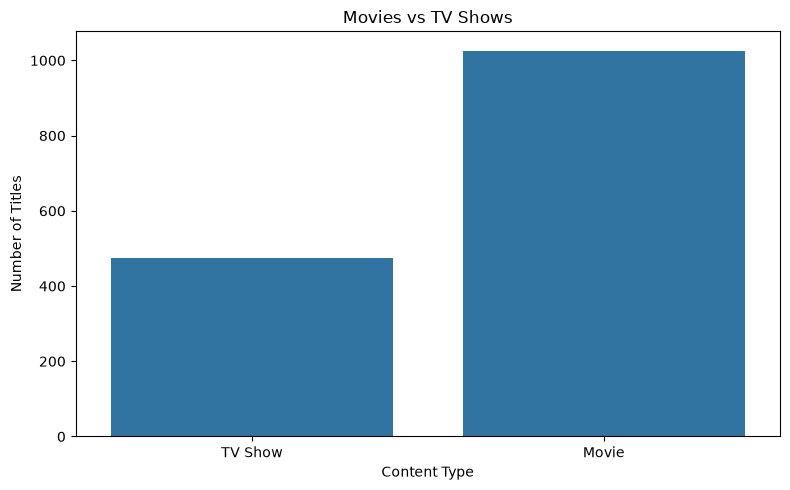

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Type"
)

plt.title("Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

## Create Pie charts

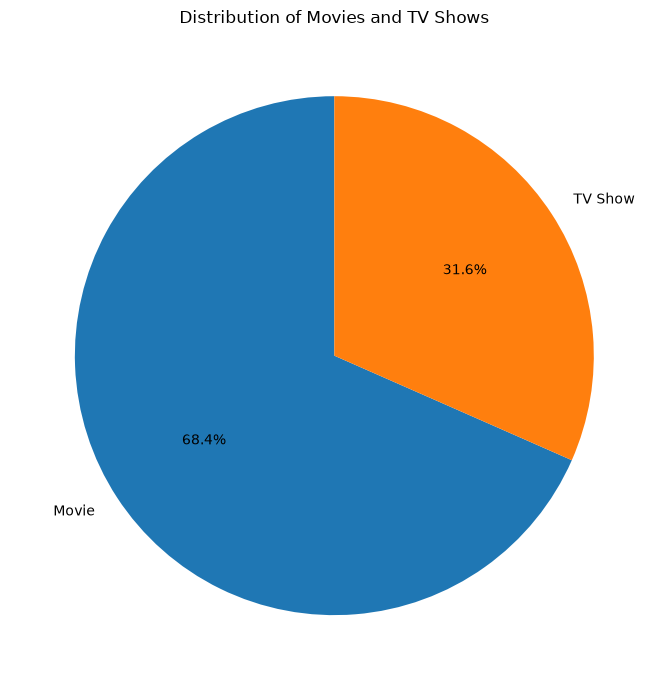

In [23]:
plt.figure(figsize=(7, 7))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Movies and TV Shows")
plt.tight_layout()
plt.show()

## Analyze genres

In [24]:
genre_counts = df["Genre"].value_counts()

print(genre_counts)

Genre
Drama          337
Comedy         292
Thriller       211
Documentary    206
Other          190
Action         160
Romance        104
Name: count, dtype: int64


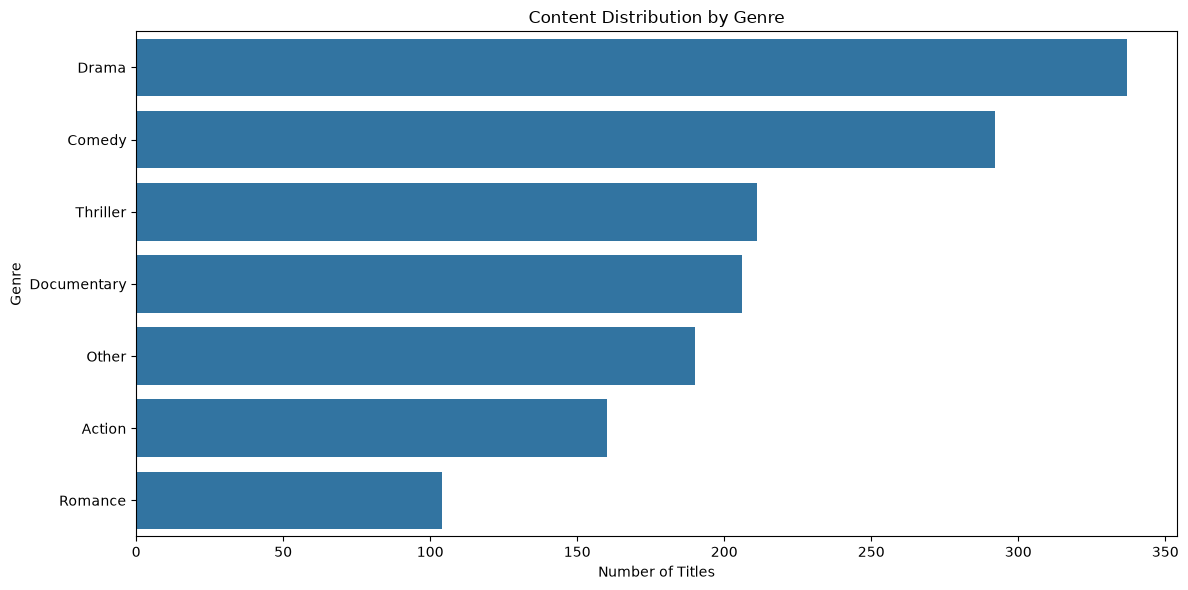

In [25]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Genre",
    order=genre_counts.index
)

plt.title("Content Distribution by Genre")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

## Analyze countries

In [26]:
country_counts = df["Country"].value_counts()

print(country_counts)

Country
United States     475
India             266
United Kingdom    190
South Korea       154
Japan             104
Canada             99
France             72
Germany            57
Spain              46
Australia          37
Name: count, dtype: int64


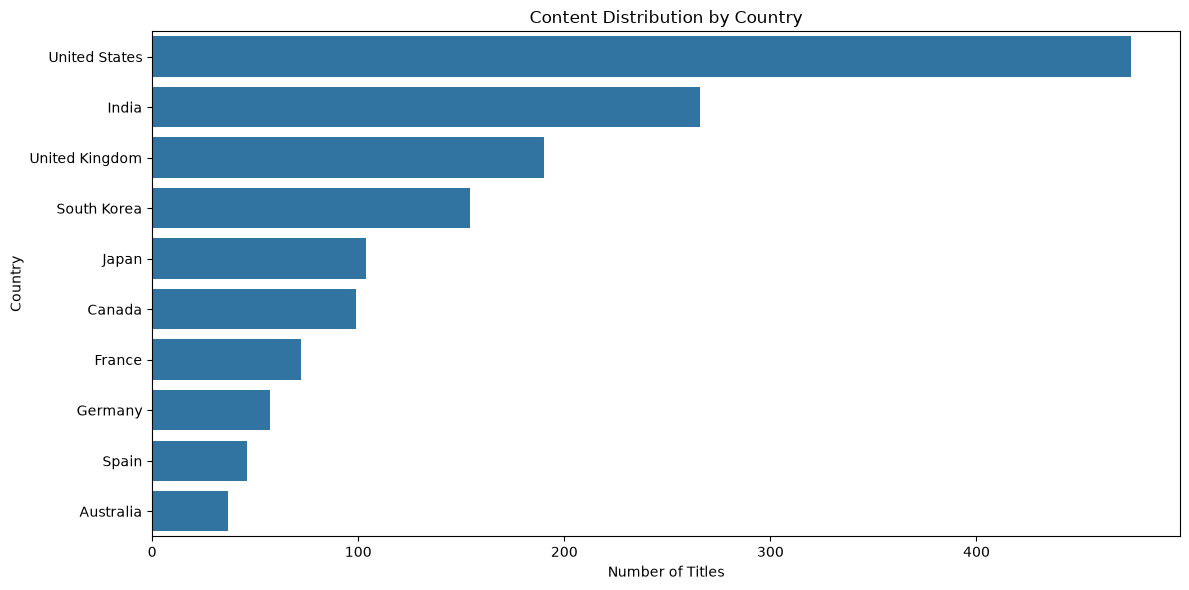

In [27]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Country",
    order=country_counts.index
)

plt.title("Content Distribution by Country")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

## Analyze content ratings

In [29]:
# Count content ratings
rating_counts = df["Rating"].value_counts()

print(rating_counts)

Rating
TV-MA    507
TV-14    437
TV-PG    216
R        157
PG-13    122
PG        35
G         16
TV-Y7     10
Name: count, dtype: int64


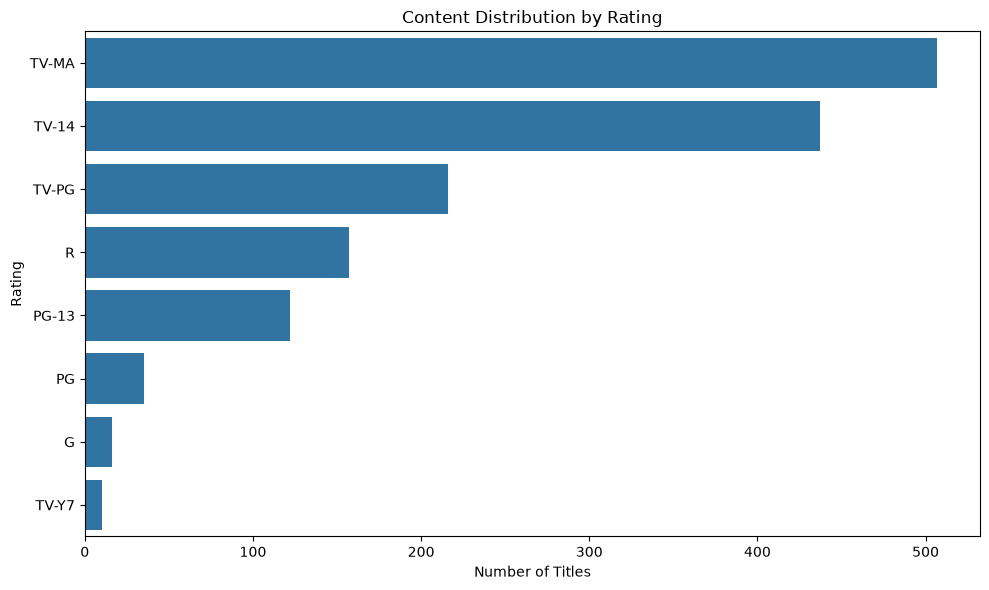

In [31]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="Rating",
    order=rating_counts.index
)

plt.title("Content Distribution by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

In [32]:
# Compare ratings by content type
ratings_comparison = pd.crosstab(
    df['Rating'],
    df['Type']    
)

print(ratings_comparison)

Type    Movie  TV Show
Rating                
G          10        6
PG         25       10
PG-13      86       36
R          93       64
TV-14     297      140
TV-MA     349      158
TV-PG     159       57
TV-Y7       7        3


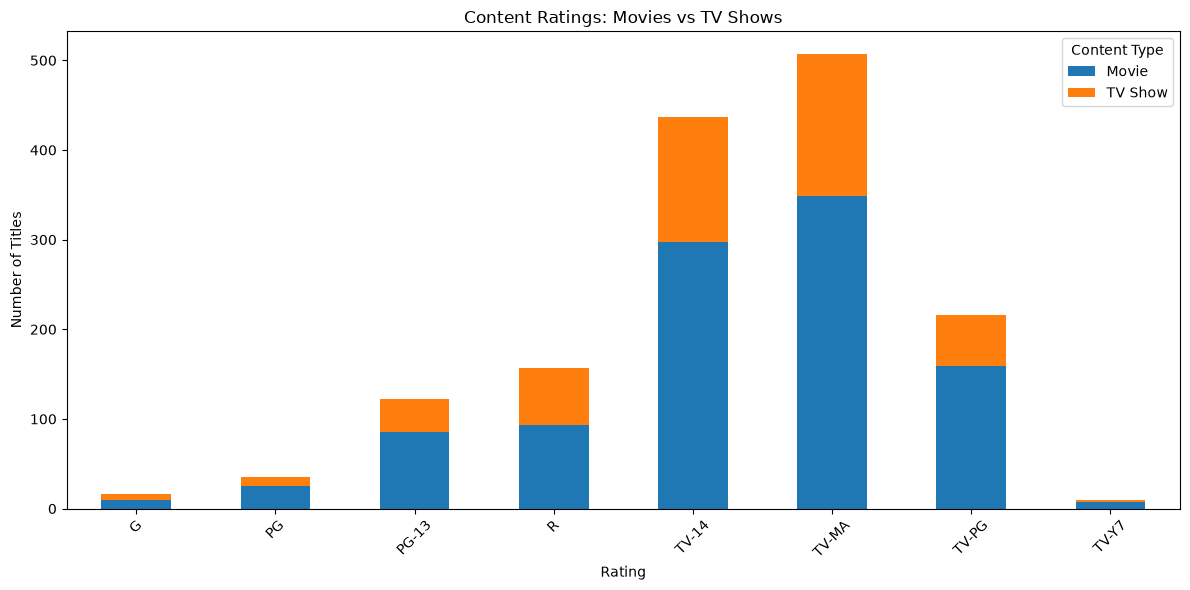

In [34]:
# Create a stacked bar chart:
ratings_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

## Analyze content duration

In [35]:
# Inspect duration values
df[["Title", "Type", "Duration"]].sample(10, random_state=42)

,Title,Type,Duration
1116,Wild Journey 1117,TV Show,8 Seasons
1368,Silent Road 1369,Movie,119 min
422,Summer Worlds 0423,Movie,160 min
413,Fading Memories 0414,Movie,150 min
451,Midnight Legacy 0452,Movie,89 min
861,Echoes of Legacy 0862,TV Show,8 Seasons
1063,Broken Light 1064,TV Show,7 Seasons
741,Blue Memories 0742,TV Show,4 Seasons
1272,Crimson Truth 1273,Movie,104 min
259,Secret Legacy 0260,Movie,137 min


In [36]:
# Separate movies and TV shows
movies = df[df["Type"] == "Movie"].copy()

tv_shows = df[df["Type"] == "TV Show"].copy()

print("Movies:", len(movies))
print("TV Shows:", len(tv_shows))

Movies: 1026
TV Shows: 474


In [37]:
# Extract movie duration in minutes
movies["Duration Minutes"] = (
    movies["Duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

movies[["Title", "Duration", "Duration Minutes"]].head(10)

,Title,Duration,Duration Minutes
1,Last Journey 0002,166 min,166.0
3,Blue Journey 0004,75 min,75.0
5,Silent Worlds 0006,82 min,82.0
6,Hidden City 0007,79 min,79.0
7,Northern Horizons 0008,94 min,94.0
8,Hidden Letters 0009,137 min,137.0
9,Wild Secrets 0010,76 min,76.0
10,Midnight Memories 0011,119 min,119.0
12,Winter Horizons 0013,124 min,124.0
13,Secret Memories 0014,124 min,124.0


In [38]:
# calculate summary statistics:
movies["Duration Minutes"].describe()

count    1026.000000
mean      119.917154
std        28.070364
min        72.000000
25%        95.000000
50%       120.000000
75%       144.750000
max       168.000000
Name: Duration Minutes, dtype: float64

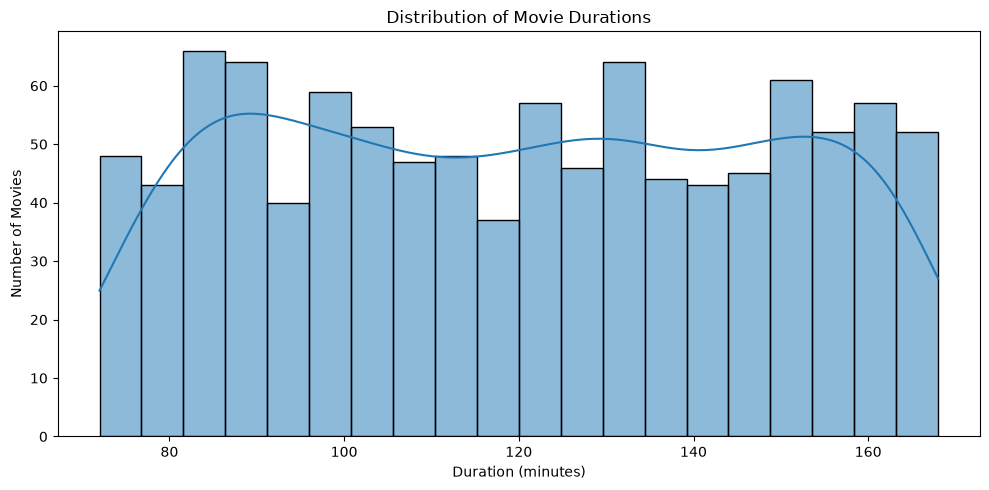

In [39]:
# Visualize movie duration
plt.figure(figsize=(10, 5))

sns.histplot(
    data=movies,
    x="Duration Minutes",
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.show()

## Analyze release-year trends

In [40]:
# Count titles by release year
release_year_counts = (
    df["Release Year"]
    .value_counts()
    .sort_index()
)

print(release_year_counts.tail(15))

Release Year
2011    55
2012    63
2013    60
2014    60
2015    57
2016    58
2017    49
2018    60
2019    39
2020    39
2021    31
2022    27
2023    18
2024     8
2025     5
Name: count, dtype: int64


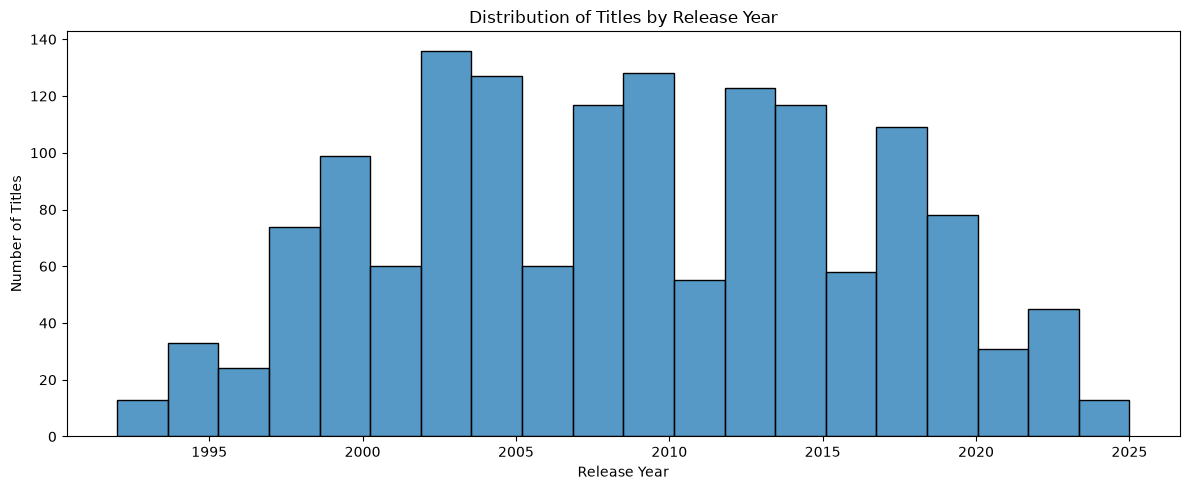

In [41]:
# Visualize release-year trends
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Release Year",
    bins=20
)

plt.title("Distribution of Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

## Calculate content age

In [42]:
# calculate the difference between the year a title was released and the year it was added to the dataset
df["Years to Add"] = df["Year Added"] - df["Release Year"]

df[["Title", "Release Year", "Year Added", "Years to Add"]].head(10)

,Title,Release Year,Year Added,Years to Add
0,Shadow Memories 0001,2008,2021,13
1,Last Journey 0002,2015,2022,7
2,Summer Promise 0003,2010,2016,6
3,Blue Journey 0004,1999,2023,24
4,Echoes of Road 0005,2002,2017,15
5,Silent Worlds 0006,2010,2023,13
6,Hidden City 0007,2006,2024,18
7,Northern Horizons 0008,2011,2025,14
8,Hidden Letters 0009,2009,2024,15
9,Wild Secrets 0010,2023,2025,2


In [43]:
df["Years to Add"].describe()

count    1500.000000
mean       11.895333
std         7.117829
min         0.000000
25%         6.000000
50%        12.000000
75%        18.000000
max        24.000000
Name: Years to Add, dtype: float64

## Analyze TV Show Seasons

In [45]:
# Extract the number of seasons
tv_shows["Seasons"] = (
    tv_shows["Duration"]
    .str.extract(r"(\d+)")
                 .astype(float)
)

tv_shows[["Title","Duration","Seasons"]].head(10)

,Title,Duration,Seasons
0,Shadow Memories 0001,1 Season,1.0
2,Summer Promise 0003,1 Season,1.0
4,Echoes of Road 0005,8 Seasons,8.0
11,Shadow Stories 0012,2 Seasons,2.0
17,Lost Journey 0018,4 Seasons,4.0
18,Beyond Legacy 0019,7 Seasons,7.0
19,Northern Stories 0020,7 Seasons,7.0
23,Fading Light 0024,8 Seasons,8.0
24,Winter Secrets 0025,2 Seasons,2.0
25,Broken Hearts 0026,8 Seasons,8.0


In [46]:
# Calculate basic statistics
print("Average number of seasons:")
print(tv_shows["Seasons"].mean())

print("\nMinimum number of seasons:")
print(tv_shows["Seasons"].min())

print("\nMaximum number of seasons:")
print(tv_shows["Seasons"].max())

Average number of seasons:
4.508438818565401

Minimum number of seasons:
1.0

Maximum number of seasons:
8.0


In [47]:
# Calculate the average, minimum, and maximum seasons
print("Average number of seasons:")
print(tv_shows["Seasons"].mean())

print("\nMinimum number of seasons:")
print(tv_shows["Seasons"].min())

print("\nMaximum number of seasons:")
print(tv_shows["Seasons"].max())

Average number of seasons:
4.508438818565401

Minimum number of seasons:
1.0

Maximum number of seasons:
8.0


## Visualize TV Show Season Distribution

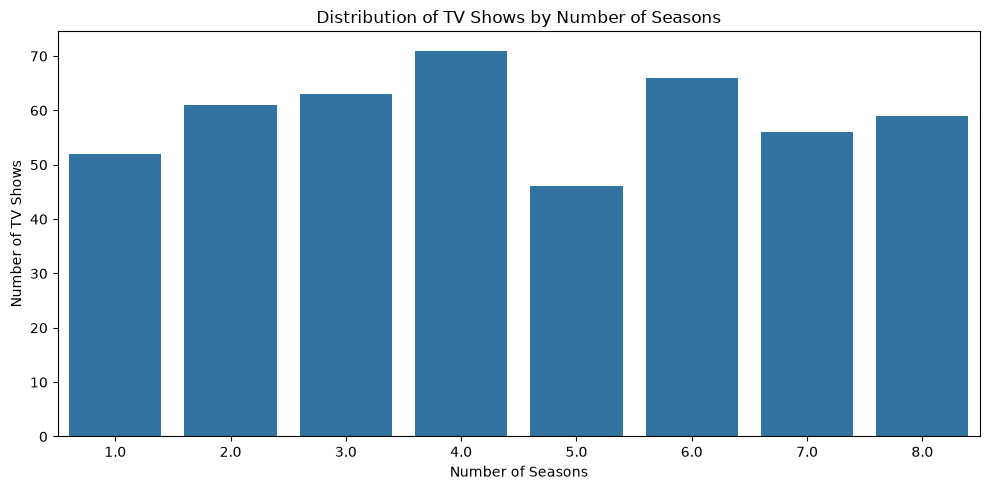

In [48]:
# We want to understand how many TV shows have 1 season, 2 seasons, 3 seasons, and so on
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=tv_shows,
    x="Seasons"
)

plt.title("Distribution of TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")

plt.tight_layout()
plt.show()

## Analyze Content Release Years

In [49]:
# Understand the release-year data
print("Earliest release year:")
print(df["Release Year"].min())

print("\nLatest release year:")
print(df["Release Year"].max())

print("\nAverage release year:")
print(df["Release Year"].mean())

Earliest release year:
1992

Latest release year:
2025

Average release year:
2008.6686666666667


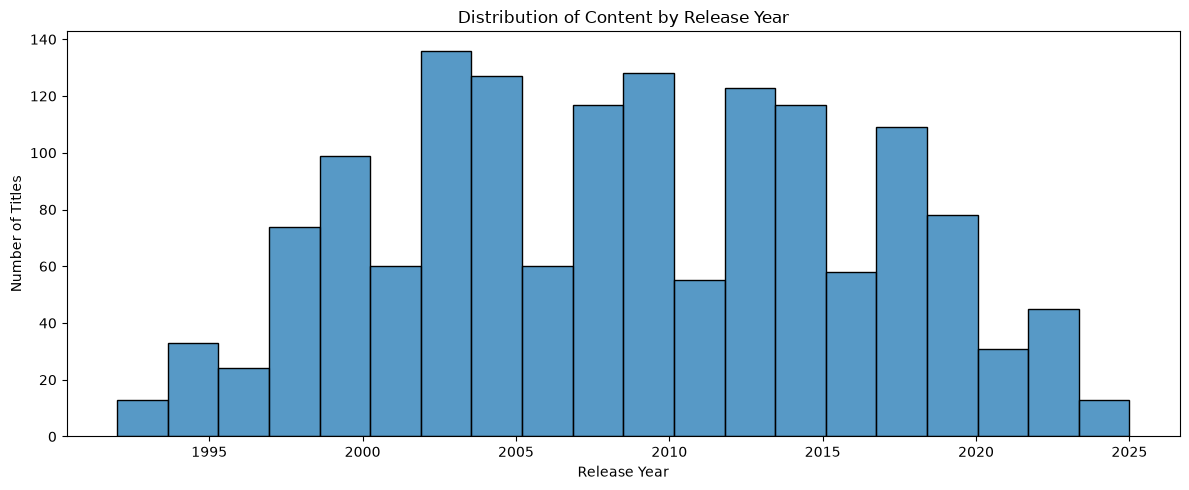

In [50]:
# Visualize the release years
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Release Year",
    bins=20
)

plt.title("Distribution of Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [51]:
# Compare older and newer content
older_content = df[df["Release Year"] <= 2005]

newer_content = df[df["Release Year"] > 2005]

print("Older content (2005 and earlier):", len(older_content))
print("Newer content (after 2005):", len(newer_content))

Older content (2005 and earlier): 566
Newer content (after 2005): 934


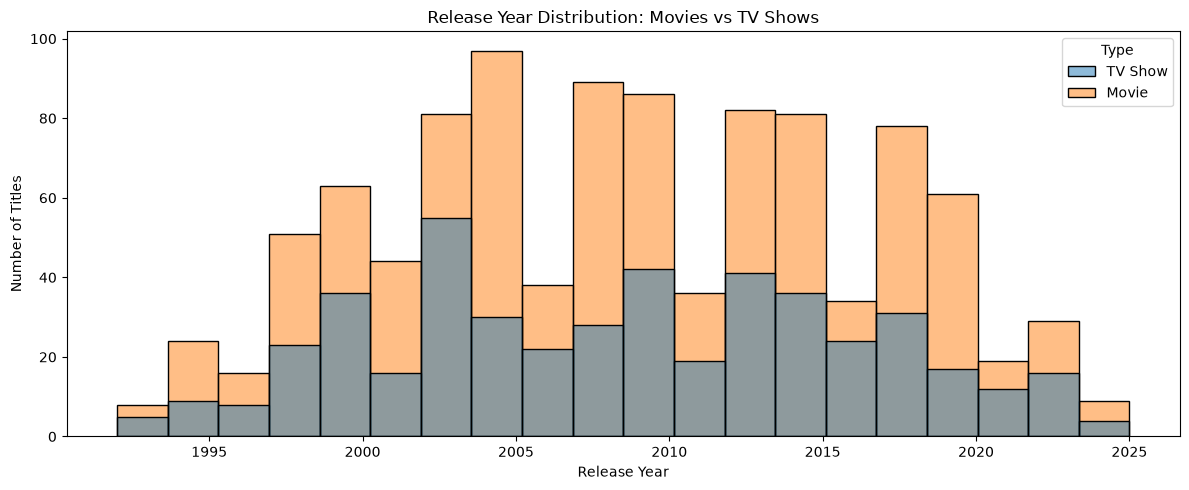

In [52]:
# Compare release years for Movies and TV Shows
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Release Year",
    hue="Type",
    bins=20,
    multiple="layer"
)

plt.title("Release Year Distribution: Movies vs TV Shows")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

## Analyze Content Added to Netflix Over Time

In [53]:
# Count titles added each year
year_added_counts = df["Year Added"].value_counts().sort_index()

print(year_added_counts)

Year Added
2016    125
2017    138
2018    160
2019    152
2020    158
2021    162
2022    159
2023    165
2024    148
2025    133
Name: count, dtype: int64


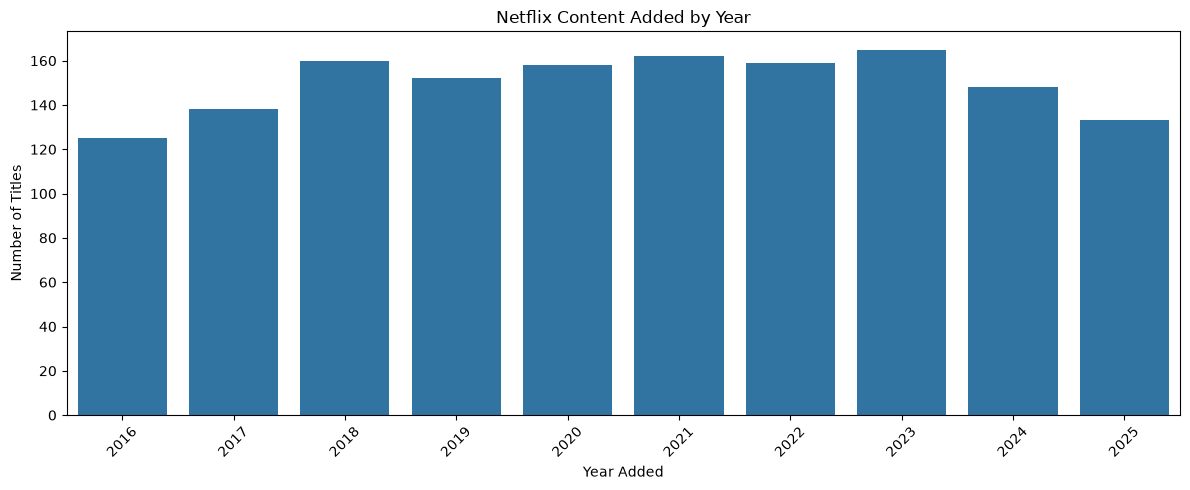

In [54]:
# Visualize Content Added Each Year
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="Year Added",
    order=sorted(df["Year Added"].unique())
)

plt.title("Netflix Content Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [55]:
# Calculate the highest and lowest years
year_added_counts = df["Year Added"].value_counts()

print("Year with the most titles added:")
print(year_added_counts.idxmax())

print("\nHighest number of titles added:")
print(year_added_counts.max())

print("\nYear with the fewest titles added:")
print(year_added_counts.idxmin())

print("\nLowest number of titles added:")
print(year_added_counts.min())

Year with the most titles added:
2023

Highest number of titles added:
165

Year with the fewest titles added:
2016

Lowest number of titles added:
125


## Analyze Content by Country

In [56]:
# Count titles by country
country_counts = df["Country"].value_counts()

print(country_counts)

Country
United States     475
India             266
United Kingdom    190
South Korea       154
Japan             104
Canada             99
France             72
Germany            57
Spain              46
Australia          37
Name: count, dtype: int64


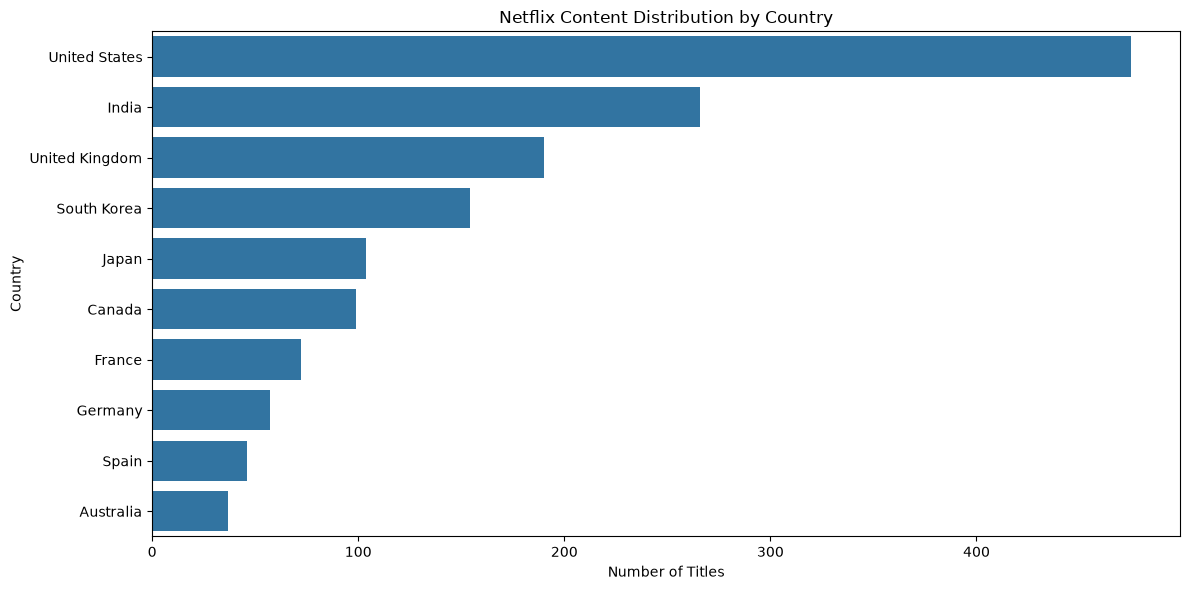

In [57]:
#Create the Country Visualization
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Country",
    order=df["Country"].value_counts().index
)

plt.title("Netflix Content Distribution by Country")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [58]:
# Calculate Country Percentages
country_counts = df["Country"].value_counts()

country_percentages = (country_counts / len(df)) * 100

print(country_percentages.round(2))

Country
United States     31.67
India             17.73
United Kingdom    12.67
South Korea       10.27
Japan              6.93
Canada             6.60
France             4.80
Germany            3.80
Spain              3.07
Australia          2.47
Name: count, dtype: float64


## Analyze Genres

In [59]:
# Count Titles by Genre
genre_counts = df["Genre"].value_counts()

print(genre_counts)

Genre
Drama          337
Comedy         292
Thriller       211
Documentary    206
Other          190
Action         160
Romance        104
Name: count, dtype: int64


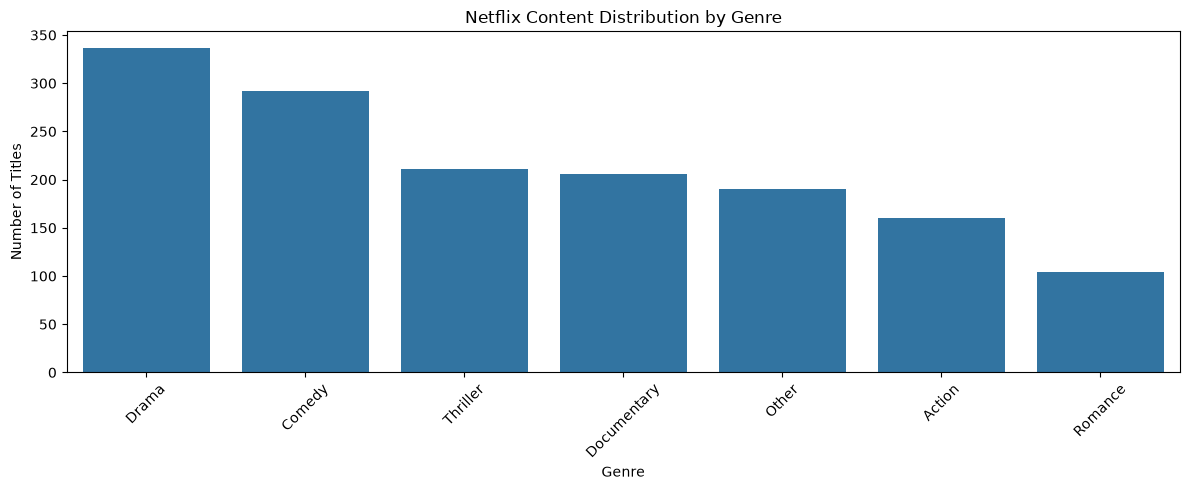

In [60]:
# Visualize Genres
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x="Genre",
    order=df['Genre'].value_counts().index
)

plt.title("Netflix Content Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [61]:
# Calculate Genre Percentages
genre_counts = df['Genre'].value_counts()
genre_percentage = (genre_counts/len(df))*100

genre_analysis = pd.DataFrame({
    "Number of Titles": genre_counts,
    "Percentage": genre_percentage.round(2)
})

print(genre_analysis)

             Number of Titles  Percentage
Genre                                    
Drama                     337       22.47
Comedy                    292       19.47
Thriller                  211       14.07
Documentary               206       13.73
Other                     190       12.67
Action                    160       10.67
Romance                   104        6.93


## Analyze Content Ratings

In [62]:
# Calculate Rating Percentages
rating_counts = df["Rating"].value_counts()
rating_percentage = (
    df["Rating"].value_counts(normalize=True)*100
)

rating_analysis = pd.DataFrame({
    "Number of Titles": rating_counts,
    "Percentage":rating_percentage.round(2)
})

print(rating_analysis)

        Number of Titles  Percentage
Rating                              
TV-MA                507       33.80
TV-14                437       29.13
TV-PG                216       14.40
R                    157       10.47
PG-13                122        8.13
PG                    35        2.33
G                     16        1.07
TV-Y7                 10        0.67


In [63]:
# Compare Ratings Between Movies and TV Shows
#Do Movies and TV Shows have different rating distributions?
#We'll use a Pandas crosstab() to compare them.

rating_by_type = pd.crosstab(# crosstab Creates a frequency table showing how two categorical variables relate to each other.
    df["Rating"],
    df["Type"]
)

print(rating_by_type)

Type    Movie  TV Show
Rating                
G          10        6
PG         25       10
PG-13      86       36
R          93       64
TV-14     297      140
TV-MA     349      158
TV-PG     159       57
TV-Y7       7        3


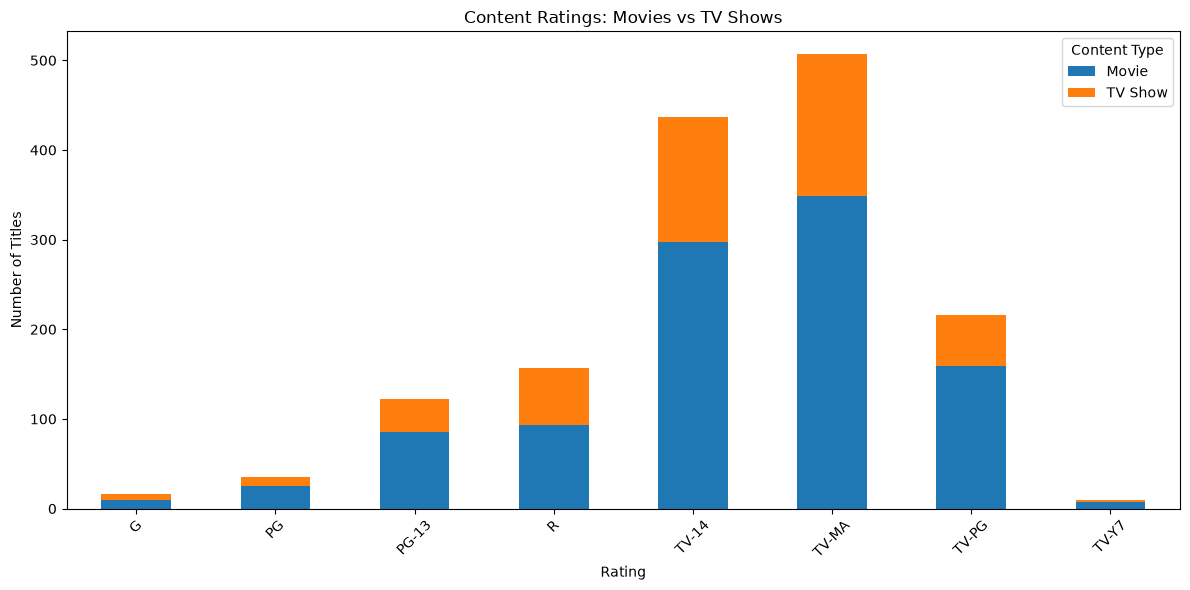

In [64]:
# Visualize Ratings by Content Type
rating_by_type.plot(
    kind="bar",
    figsize=(12, 6),
    stacked=True
)

plt.title("Content Ratings: Movies vs TV Shows")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")

plt.tight_layout()
plt.show()

## Analyze How Old Content Was When Added to Netflix

In [65]:
# Create a New Column
df["Years Until Added"] = df["Year Added"] - df["Release Year"]

df[["Title", "Release Year", "Year Added", "Years Until Added"]].head(10)

,Title,Release Year,Year Added,Years Until Added
0,Shadow Memories 0001,2008,2021,13
1,Last Journey 0002,2015,2022,7
2,Summer Promise 0003,2010,2016,6
3,Blue Journey 0004,1999,2023,24
4,Echoes of Road 0005,2002,2017,15
5,Silent Worlds 0006,2010,2023,13
6,Hidden City 0007,2006,2024,18
7,Northern Horizons 0008,2011,2025,14
8,Hidden Letters 0009,2009,2024,15
9,Wild Secrets 0010,2023,2025,2


In [66]:
# Calculate the Average Years Until Added
print("Average years until added:")
print(df["Years Until Added"].mean())

print("\nMinimum years until added:")
print(df["Years Until Added"].min())

print("\nMaximum years until added:")
print(df["Years Until Added"].max())

Average years until added:
11.895333333333333

Minimum years until added:
0

Maximum years until added:
24


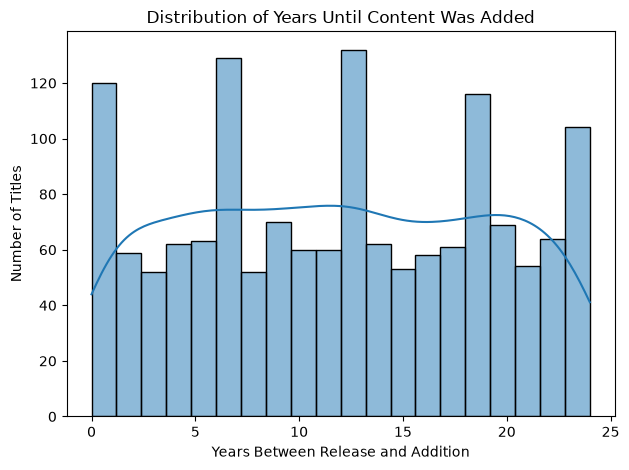

In [67]:

# Visualize the Years Until Addedplt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Years Until Added",
    bins=20,
    kde=True
)

plt.title("Distribution of Years Until Content Was Added")
plt.xlabel("Years Between Release and Addition")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [68]:
# Find the Most Common Time Difference
print("Most common years until added:")
print(df["Years Until Added"].mode()[0])

print("\nMedian years until added:")
print(df["Years Until Added"].median())

Most common years until added:
9

Median years until added:
12.0


print("Titles added in the same release year:")
print((df["Years Until Added"] == 0).sum())

print("\nTitles added within 5 years of release:")
print(((df["Years Until Added"] >= 0) &
       (df["Years Until Added"] <= 5)).sum())

print("\nTitles added more than 20 years after release:")
print((df["Years Until Added"] > 20).sum())

## Analyze Content by Type and Year Added

In [71]:
# Create a Cross-Tabulation
content_by_year = pd.crosstab(
    df["Year Added"],
    df["Type"]
)

print(content_by_year)

Type        Movie  TV Show
Year Added                
2016           87       38
2017           98       40
2018          116       44
2019          102       50
2020          112       46
2021          101       61
2022          117       42
2023          112       53
2024           92       56
2025           89       44


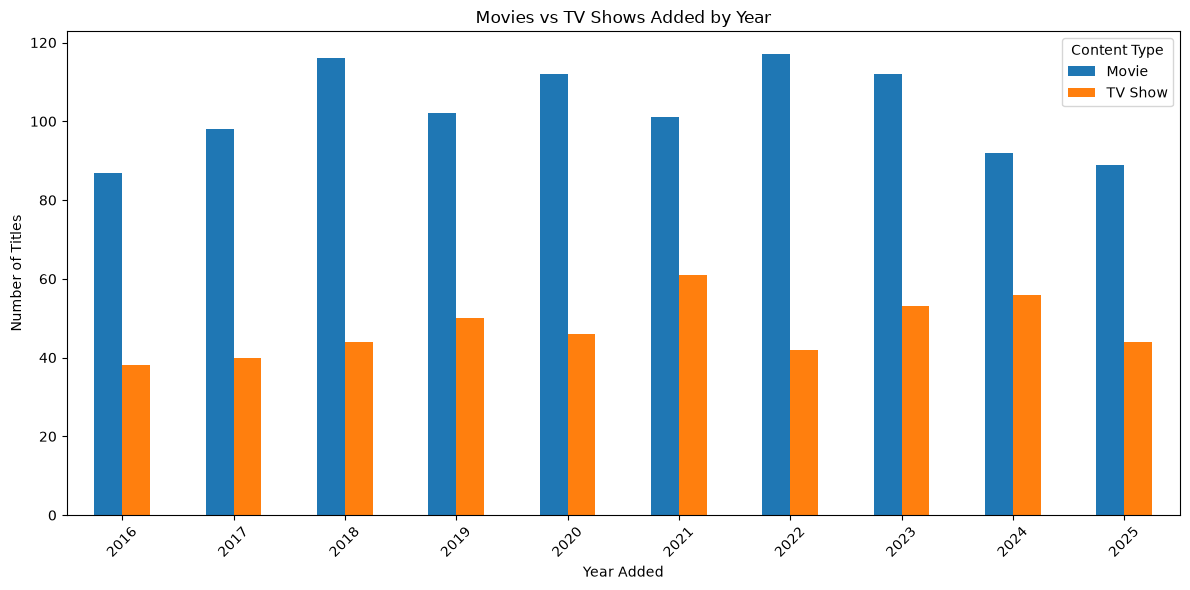

In [72]:
# Visualize Movies vs. TV Shows by Year
content_by_year.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()